# Brain Tumour Detection from MRI: End-to-End Pipeline

This notebook walks through the pipeline in `src/brain_tumor/`. It does **not** re-implement
any logic. It calls the same functions that the training script and the Flask app use, so the
results shown here are the results that ship.

| Stage | Module |
|---|---|
| 1. Ingest + 2. Validate + 3. Split | `brain_tumor.data` |
| 4. Preprocess | `brain_tumor.preprocess` |
| 5. Model | `brain_tumor.models` |
| 6. Model selection (5-fold grouped CV) | `brain_tumor.experiments` |
| 7. Final training + held-out test | `brain_tumor.train`, `brain_tumor.evaluate` |
| 8. Serve | `app.py` |

> Before running, train once from the repo root:
> `PYTHONPATH=src python -m brain_tumor.experiments` and `PYTHONPATH=src python -m brain_tumor.train --model cnn`.
> This notebook reads the artifacts those commands write.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from brain_tumor.config import load_config, resolve
from brain_tumor.data import build_manifest
from brain_tumor.preprocess import crop_to_brain, load_and_preprocess

cfg = load_config()
CLASS = {0: "no tumour", 1: "tumour"}

## 1–3. Ingest, validate, split

Each label comes from an explicit folder→label map in `configs/config.yaml` (`no`→0, `yes`→1).
The original notebook took labels from `os.listdir()` order. On Colab that order was `['yes', 'no']`,
so tumour images got label **0**. The app then printed "has Brain Tumor" when the model said
label 1, which meant the healthy class. **Every prediction was reported backwards.**

In [2]:
df = build_manifest(cfg)          # writes data/processed/manifest.csv + reports/data_quality.json
df.groupby(["split", "label"]).size().unstack().rename(columns=CLASS)

{
  "n_images": 253,
  "unreadable": [],
  "class_counts": {
    "0": 98,
    "1": 155
  },
  "exact_duplicate_files": 25,
  "near_duplicate_groups": 32,
  "images_in_duplicate_groups": 73,
  "split_counts": {
    "test": {
      "0": 14,
      "1": 23
    },
    "train": {
      "0": 70,
      "1": 110
    },
    "val": {
      "0": 14,
      "1": 22
    }
  }
}


label,no tumour,tumour
split,,
test,14,23
train,70,110
val,14,22


### Duplicates

25 files are byte-identical copies, and more scans were re-saved at another size. Copies of one
scan are kept in the **same** split. Otherwise the model is "tested" on images it already trained on.

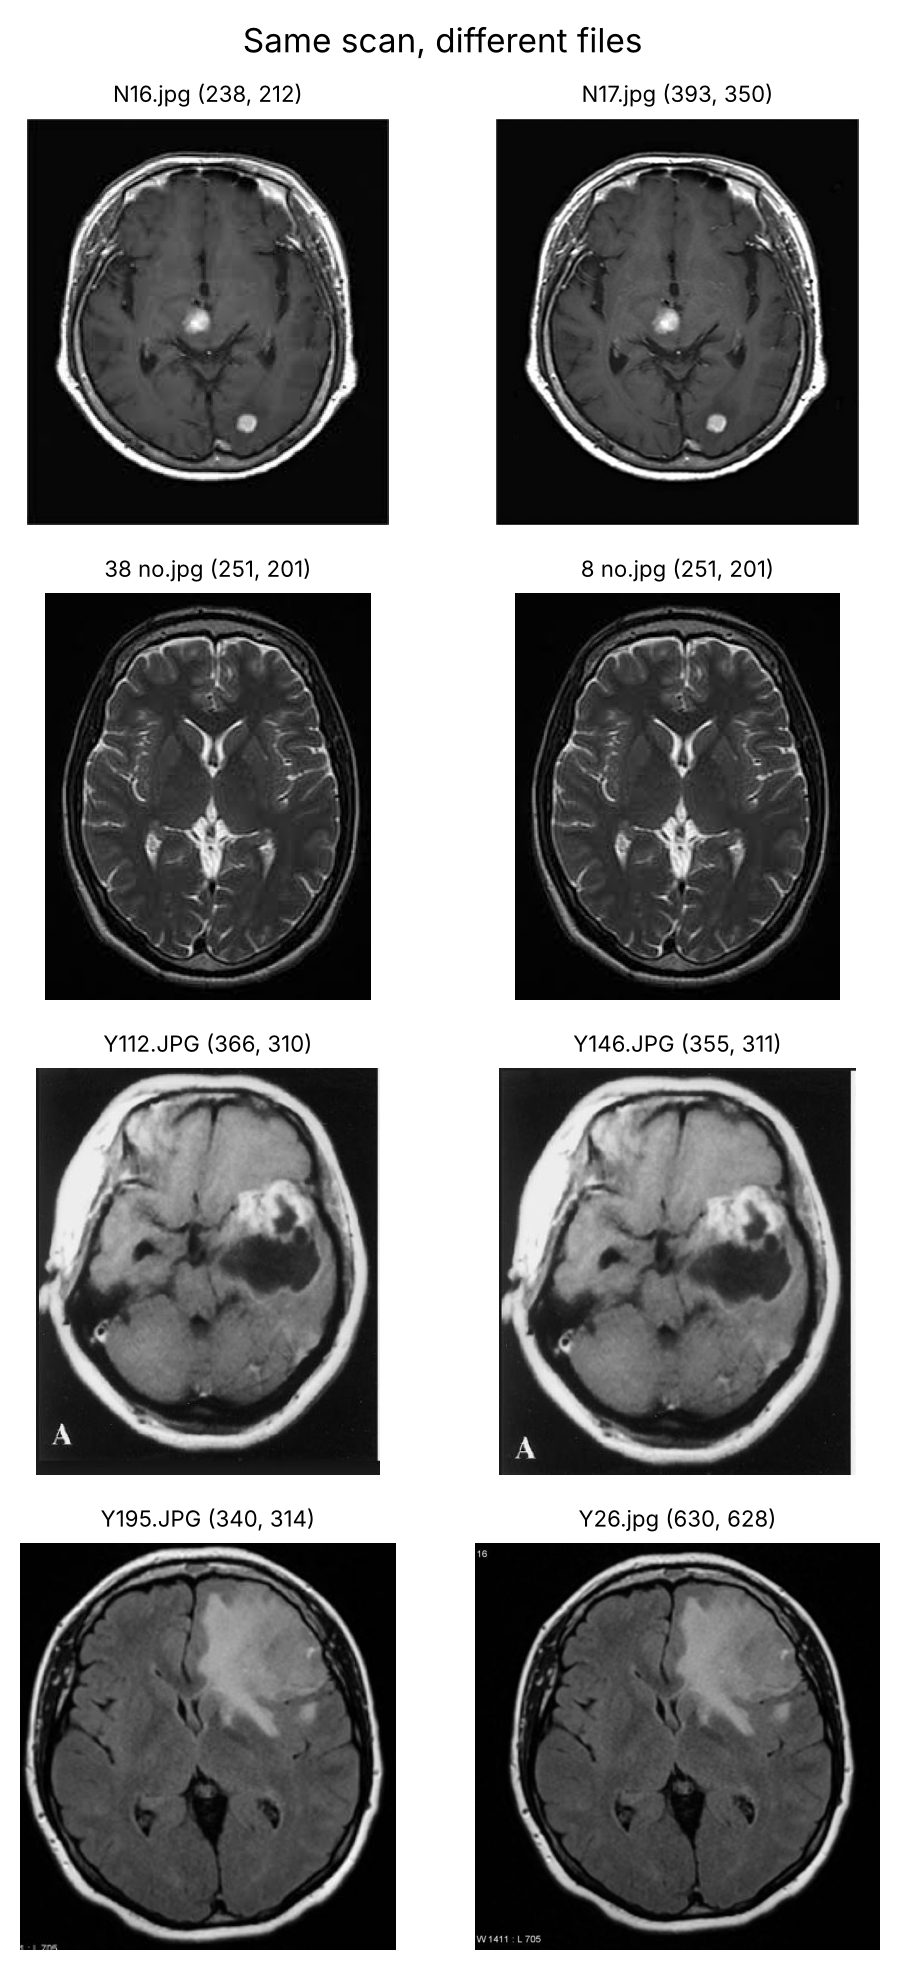

In [3]:
multi = df.groupby("group").filter(lambda g: len(g) > 1 and g.md5.nunique() > 1)
groups = list(multi.groupby("group"))[:4]
fig, axes = plt.subplots(len(groups), 2, figsize=(5, 2.5 * len(groups)))
for r, (gid, g) in enumerate(groups):
    for c, (_, row) in enumerate(list(g.iterrows())[:2]):
        im = cv2.imread(str(resolve(row.path)), 0)
        axes[r, c].imshow(im, cmap="gray"); axes[r, c].set_title(f"{Path(row.path).name} {im.shape}", fontsize=8)
        axes[r, c].axis("off")
plt.suptitle("Same scan, different files"); plt.tight_layout()

## EDA: class balance and image sizes

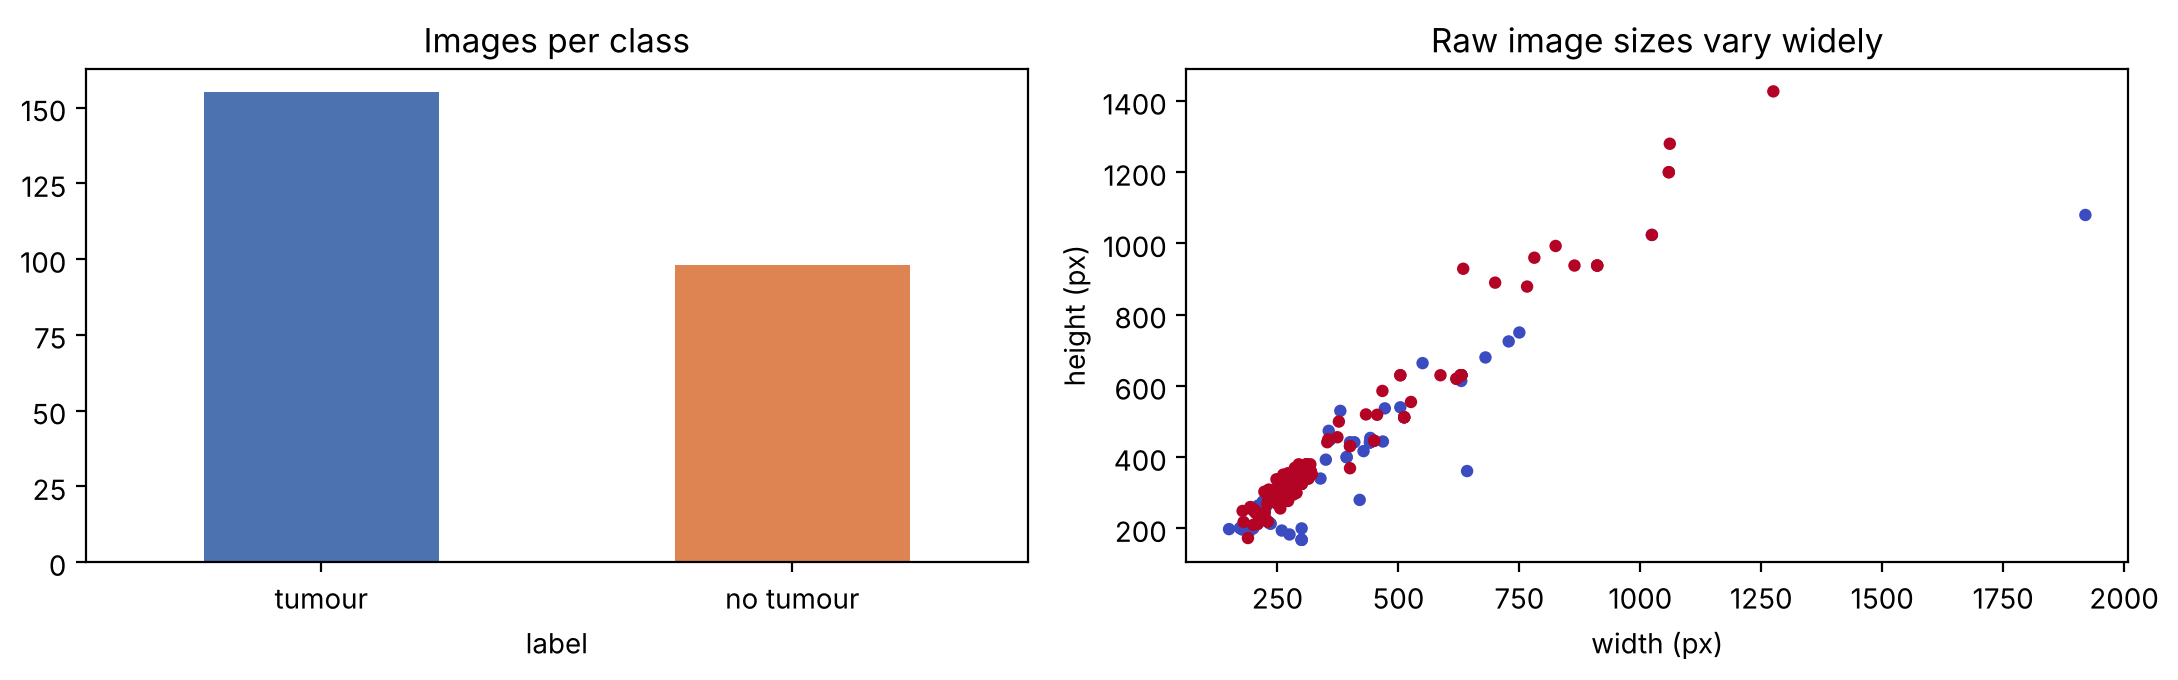

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df.label.map(CLASS).value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#DD8452"], rot=0, title="Images per class")
ax[1].scatter(df.width, df.height, c=df.label, cmap="coolwarm", s=12)
ax[1].set_xlabel("width (px)"); ax[1].set_ylabel("height (px)"); ax[1].set_title("Raw image sizes vary widely")
plt.tight_layout()

## 4. Preprocessing

Grayscale → crop to the brain (largest contour) → resize to 128×128 → scale /255.
The Flask app runs this **same function**. The original app fed 224×224 RGB images into a model
trained on 128×128 grayscale, so it crashed on every request.

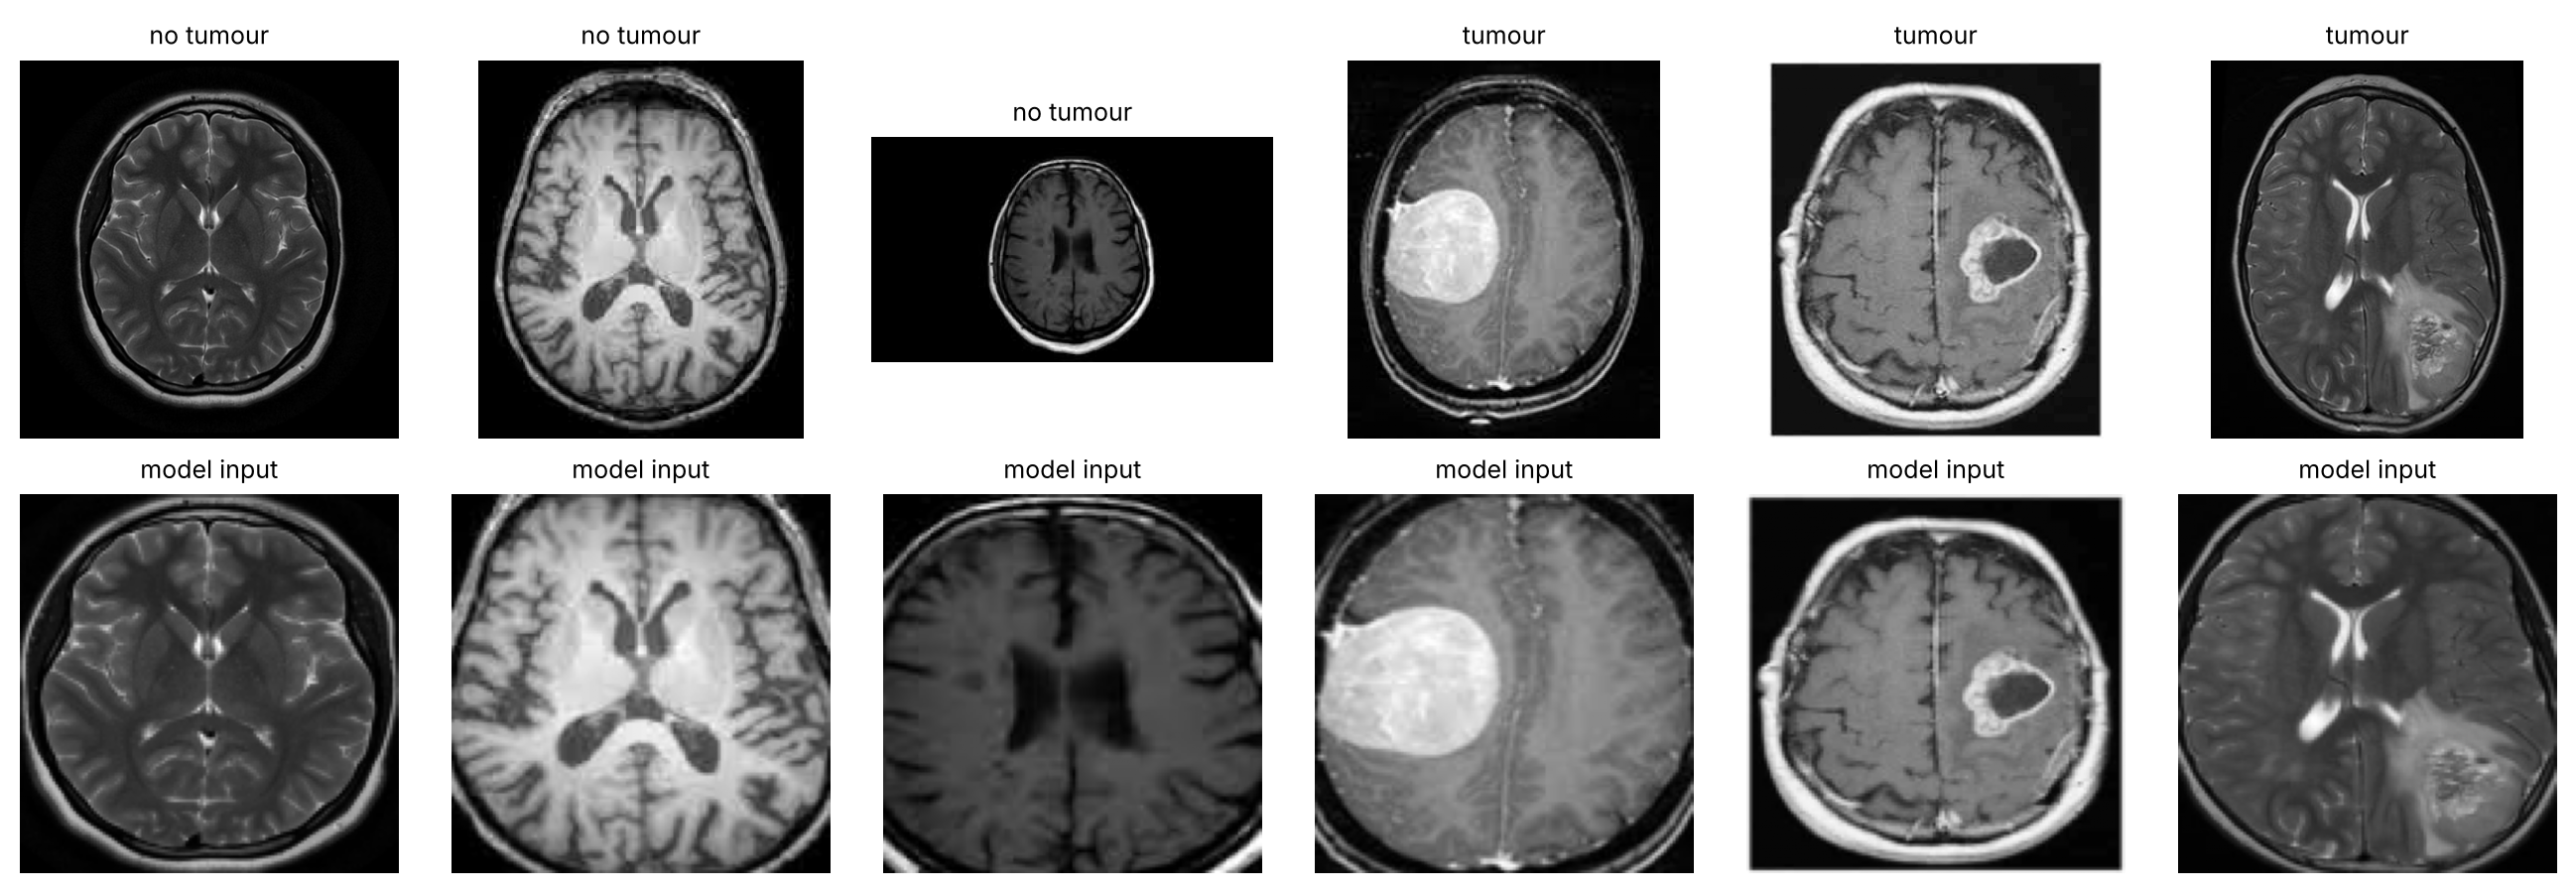

In [5]:
sample = df.groupby("label").head(3)
fig, axes = plt.subplots(2, len(sample), figsize=(2.2 * len(sample), 4.6))
for i, (_, row) in enumerate(sample.iterrows()):
    raw = cv2.imread(str(resolve(row.path)), 0)
    axes[0, i].imshow(raw, cmap="gray"); axes[0, i].set_title(CLASS[row.label], fontsize=9)
    axes[1, i].imshow(load_and_preprocess(resolve(row.path))[..., 0], cmap="gray"); axes[1, i].set_title("model input", fontsize=9)
    for a in axes[:, i]: a.axis("off")
plt.tight_layout()

## 5–6. Model selection with 5-fold grouped cross-validation

Three candidates are scored on the development set (train+val). The test set is not touched:

- **logreg**: logistic regression on 32×32 pixels (non-deep baseline)
- **cnn**: small CNN with batch-norm, dropout, augmentation and early stopping
- **lstm**: bidirectional LSTM that reads the image row by row

With only ~43 images per fold, the ± values matter as much as the means.

In [6]:
cv = json.loads((ROOT / "reports" / "cv_results.json").read_text())
keys = ["roc_auc", "balanced_accuracy", "sensitivity_recall", "specificity", "f1"]
pd.DataFrame({m: {k: f"{cv[m][k]['mean']:.3f} ± {cv[m][k]['std']:.3f}" for k in keys} for m in cv}).T

,roc_auc,balanced_accuracy,sensitivity_recall,specificity,f1
logreg,0.696 ± 0.067,0.640 ± 0.076,0.576 ± 0.146,0.704 ± 0.096,0.642 ± 0.116
cnn,0.768 ± 0.052,0.704 ± 0.041,0.695 ± 0.124,0.713 ± 0.074,0.735 ± 0.075
lstm,0.539 ± 0.067,0.499 ± 0.049,0.527 ± 0.228,0.471 ± 0.320,0.539 ± 0.127


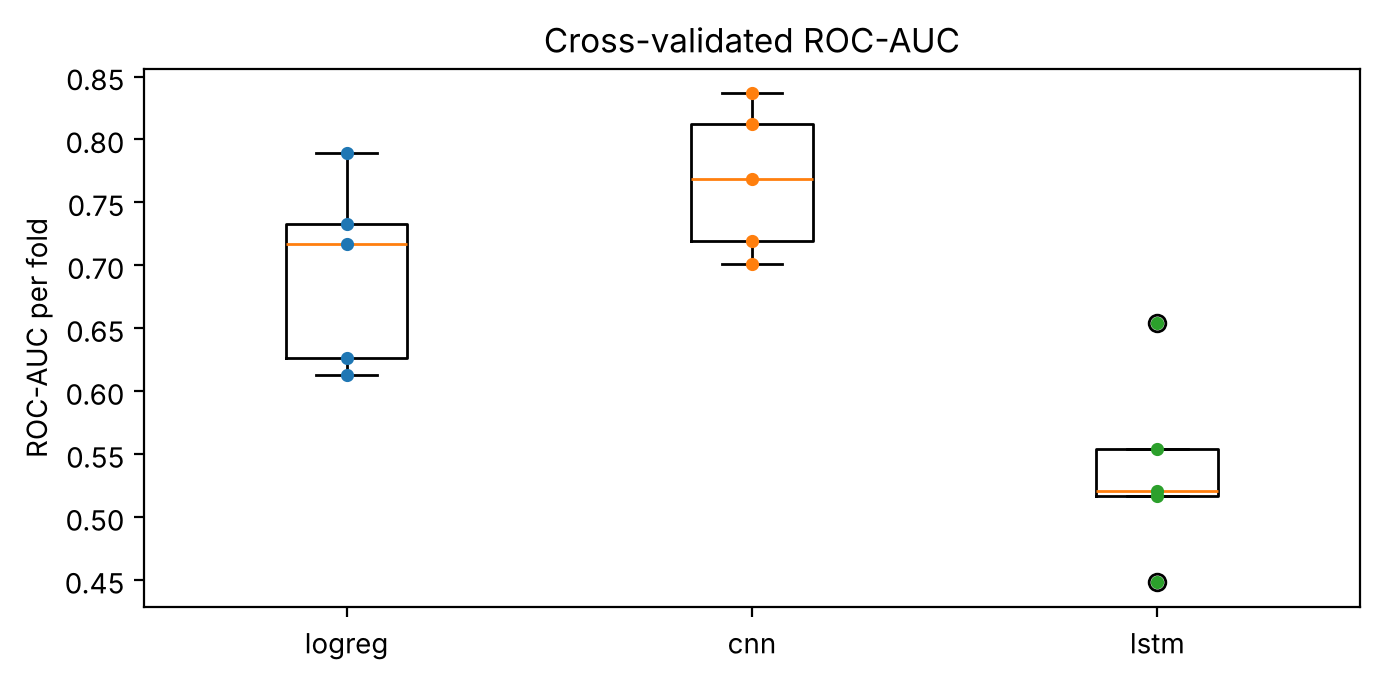

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
data = [[f["roc_auc"] for f in cv[m]["folds"]] for m in cv]
ax.boxplot(data); ax.set_xticks(range(1, len(cv) + 1), list(cv)); ax.set_ylabel("ROC-AUC per fold"); ax.set_title("Cross-validated ROC-AUC")
for i, d in enumerate(data, 1): ax.scatter([i] * len(d), d, s=14, zorder=3)
plt.tight_layout()

## 7. Final model: held-out test set (used once)

The decision threshold is picked on the validation set (Youden's J) and then frozen.
The 95% bootstrap intervals are wide because the test set has only ~37 images.

In [8]:
meta = json.loads((ROOT / "models" / "brain_tumor_cnn.json").read_text())
t = meta["test_metrics"]
print(f"threshold = {meta['threshold']:.2f}   (epochs trained: {meta['epochs_trained']})")
pd.DataFrame({
    "value": {k: round(t[k], 3) for k in ["roc_auc", "accuracy", "balanced_accuracy", "sensitivity_recall", "specificity", "precision", "f1"]},
    "95% CI": {k: f"[{v[0]:.2f}, {v[1]:.2f}]" for k, v in t["ci95"].items()},
})

threshold = 0.63   (epochs trained: 31)


,value,95% CI
roc_auc,0.752,"[0.55, 0.92]"
accuracy,0.703,"[0.54, 0.84]"
balanced_accuracy,0.719,NaN
sensitivity_recall,0.652,"[0.46, 0.84]"
specificity,0.786,"[0.54, 1.00]"
precision,0.833,NaN
f1,0.732,NaN


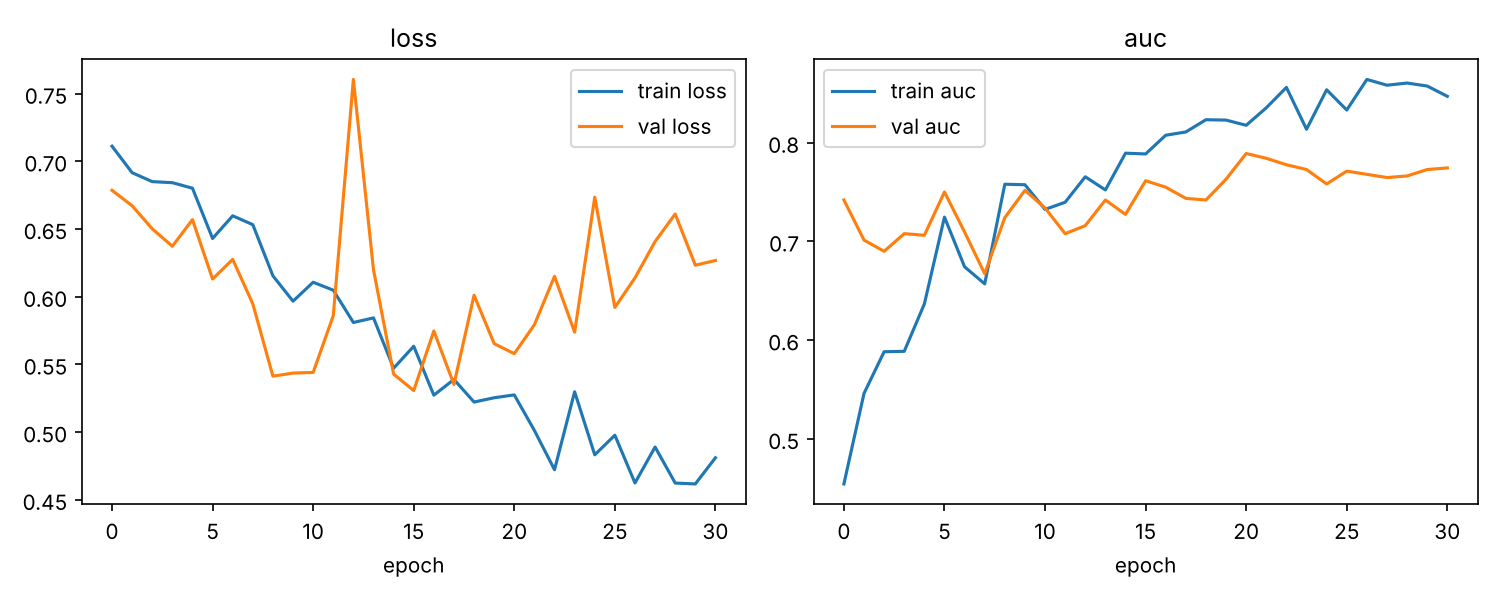

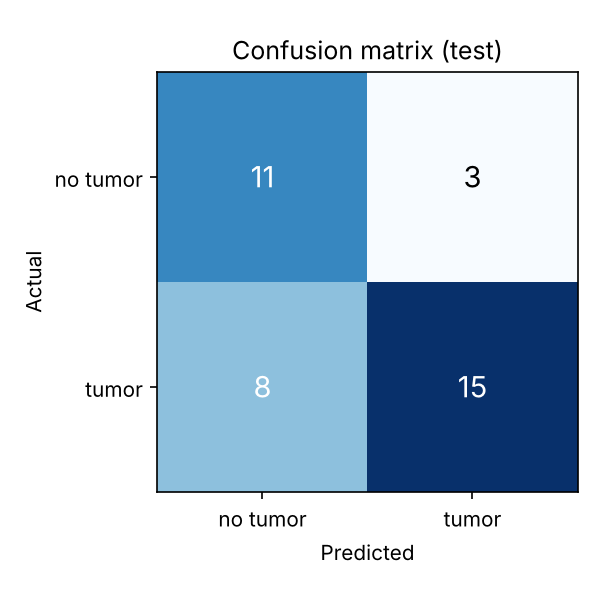

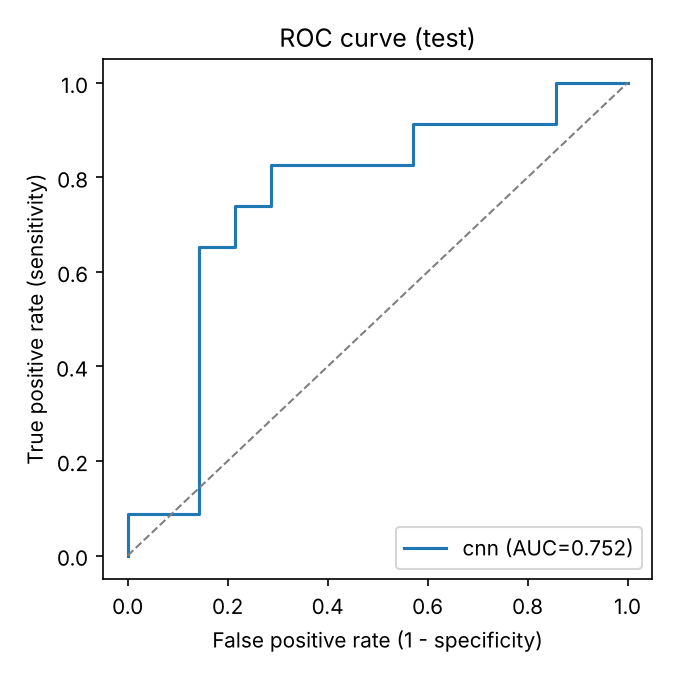

In [9]:
from IPython.display import Image, display
for f in ["cnn_training_curves.png", "cnn_confusion_matrix.png", "cnn_roc.png"]:
    display(Image(filename=str(ROOT / "reports" / "figures" / f), width=520))

## Error analysis: which test images does the model get wrong?

I0000 00:00:1795556954.507761   18072 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795556958.667856   18072 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


11 of 37 test images misclassified


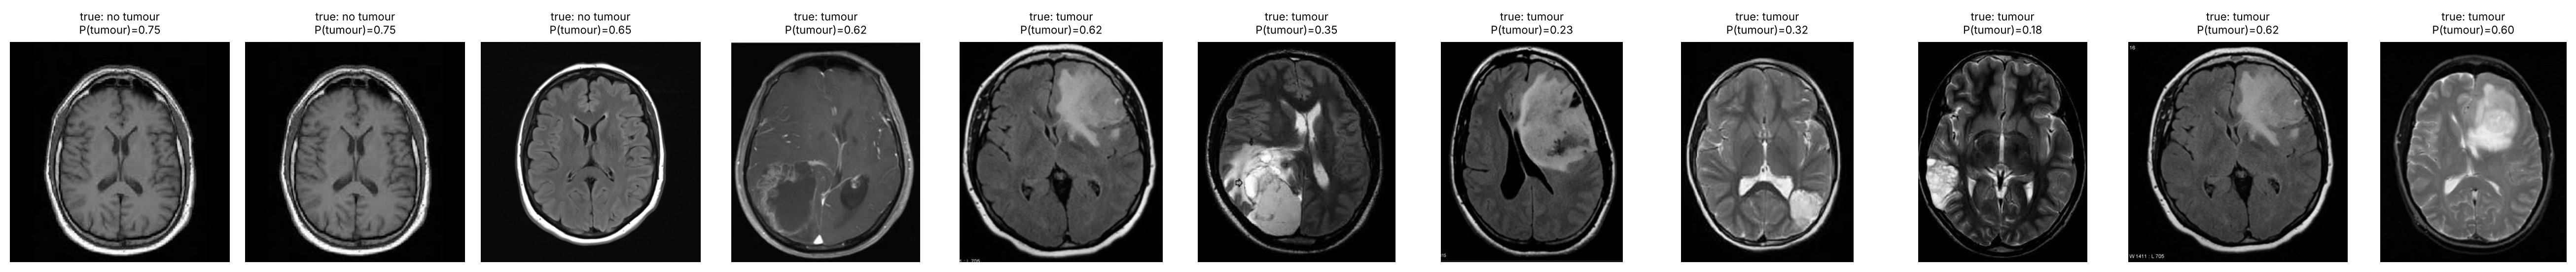

In [10]:
import tensorflow as tf
model = tf.keras.models.load_model(ROOT / "models" / meta["model_file"])
test = df[df.split == "test"].reset_index(drop=True)
X = np.stack([load_and_preprocess(resolve(p)) for p in test.path])
test["p_tumour"] = model.predict(X, verbose=0).ravel()
test["pred"] = (test.p_tumour >= meta["threshold"]).astype(int)
wrong = test[test.pred != test.label]
print(f"{len(wrong)} of {len(test)} test images misclassified")
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.4 * len(wrong), 2.8), squeeze=False)
    for a, (_, r) in zip(axes[0], wrong.iterrows()):
        a.imshow(cv2.imread(str(resolve(r.path)), 0), cmap="gray"); a.axis("off")
        a.set_title(f"true: {CLASS[r.label]}\nP(tumour)={r.p_tumour:.2f}", fontsize=8)
    plt.tight_layout()

## Conclusions

- The CNN is the right model family here. The LSTM treats image rows as a time series, which
  throws away 2D spatial structure, and it scores worse in cross-validation. RNNs and LSTMs fit
  *sequences*, such as a stack of MRI slices or follow-up scans over time. They don't fit one 2D slice.
- **The original 91.7% "accuracy" was not a valid result.** It was computed on images the model had
  trained on. The original validation set was 100% "no tumour" images, because Keras'
  `validation_split` takes the *last* 20% of the array before shuffling.
- Next steps: transfer learning (`--model transfer`, MobileNetV2 on ImageNet; needs internet for
  the weights), more data (for example the 7k-image Figshare/BraTS-derived sets), and Grad-CAM to
  check that the model looks at the lesion and not at scanner artefacts.

*Research and education only. This is not a diagnostic tool.*